# 전체 연속 데이터 재생과 더 빠른 경보 후보 검증

이벤트 주변 24시간 표본에서 계산한 오탐률은 실제 장기 운영을 낙관할 수 있습니다. 이 노트북은 두 모델을 6개 반응기의 전체 90일 시계열에 1분씩 재생합니다.

1. 현재 최적화 모델: 6시간 기준 특징, 확률 0.35, 2분 연속
2. 빠른 경보 후보: 5분 평균·EWMA 특징 추가, 확률 0.275, 2분 연속

평가 항목은 전체 정상 시간의 24시간당 오탐, 35개 결함 이벤트 탐지율과 탐지 지연입니다.

중요한 한계가 있습니다. 두 모델은 이 데이터의 일부 이벤트로 학습됐으므로 전체 재생의 탐지 지연은 독립 Test 성능이 아닙니다. 전체 재생은 주로 장기 오탐과 파이프라인 동작을 점검하는 엔지니어링 검증입니다.


## 0. 데이터와 모델 준비

실시간 전처리 원본에서 모든 특징을 다시 계산합니다. 이벤트 표본에서 미리 계산된 특징을 재사용하지 않으므로 실제 스트림 특징 생성과 같은 경로를 검증할 수 있습니다.


In [1]:
from pathlib import Path
import json,warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
import joblib

warnings.filterwarnings('ignore',message='FigureCanvasAgg is non-interactive.*');warnings.filterwarnings('ignore',category=pd.errors.PerformanceWarning)
pd.set_option('display.width',190);pd.set_option('display.max_columns',40);pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
plt.style.use('seaborn-v0_8-whitegrid');plt.rcParams.update({'font.family':'Nanum Gothic','axes.unicode_minus':False,'font.size':9})

RAW=Path('data/processed/chemical_process_timeseries_realtime_ffill.csv.gz');EVENT_DATA=Path('data/modeling/realtime_event_features.csv.gz');SCHEMA=Path('data/modeling/feature_schema.json');CURRENT_MODEL_PATH=Path('models/binary_fault_detector_hgb_optimized.joblib');CURRENT_CONFIG=Path('models/binary_fault_detector_optimized_config.json')
if not RAW.exists(): RAW=Path('../data/processed/chemical_process_timeseries_realtime_ffill.csv.gz');EVENT_DATA=Path('../data/modeling/realtime_event_features.csv.gz');SCHEMA=Path('../data/modeling/feature_schema.json');CURRENT_MODEL_PATH=Path('../models/binary_fault_detector_hgb_optimized.joblib');CURRENT_CONFIG=Path('../models/binary_fault_detector_optimized_config.json')

schema=json.loads(SCHEMA.read_text());base_features=schema['feature_columns'];current_model=joblib.load(CURRENT_MODEL_PATH);current_config=json.loads(CURRENT_CONFIG.read_text())
event_df=pd.read_csv(EVENT_DATA).sort_values(['sample_event_id','relative_min']).reset_index(drop=True)
raw=pd.read_csv(RAW,parse_dates=['timestamp']).sort_values(['reactor_id','timestamp']).reset_index(drop=True)
sensor_cols=['reactor_temp','reactor_pressure','feed_flow_rate','coolant_flow_rate','agitator_speed_rpm','reaction_rate','conversion_rate','selectivity','yield_pct','vibration_rms','motor_current','power_consumption_kw']
setpoint_cols=['temp_setpoint','pressure_setpoint'];missing_flags=[c for c in raw.columns if c.endswith('__was_missing')]
print(f'연속 재생 데이터: {len(raw):,}행, 반응기 {raw.reactor_id.nunique()}개, 기간 {raw.timestamp.min()} ~ {raw.timestamp.max()}')


연속 재생 데이터: 777,600행, 반응기 6개, 기간 2024-01-01 00:00:00 ~ 2024-03-30 23:59:00


## 1. 빠른 경보 후보 학습

현재 모델의 6시간 기준 특징에 다음 특징을 추가합니다.

- 5분 이동평균의 6시간 기준 z-score
- 5분 EWMA의 6시간 기준 z-score
- 15분 EWMA의 6시간 기준 z-score

EWMA는 최근 관측에 더 큰 가중치를 주어 변화 직후 빠르게 반응합니다. 이벤트 Validation에서 100% 탐지와 24시간당 오탐 1건 이하를 만족하는 설정 중 지연이 가장 짧은 후보를 선택합니다.


In [2]:
def add_long_baseline_features(data,fast=False,group_col='sample_event_id'):
    grouped=data.groupby(group_col,sort=False);parts=[];names=[]
    for col in sensor_cols:
        mean6=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).mean());std6=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).std()).replace(0,np.nan)
        values={f'{col}__z_6h':(data[col]-mean6)/std6,f'{col}__mean15_vs_6h':(data[f'{col}__mean_15m']-mean6)/std6}
        if fast:
            values.update({f'{col}__mean5_vs_6h':(data[f'{col}__mean_5m']-mean6)/std6,f'{col}__ewm5_vs_6h':(grouped[col].transform(lambda x:x.ewm(span=5,adjust=False).mean())-mean6)/std6,f'{col}__ewm15_vs_6h':(grouped[col].transform(lambda x:x.ewm(span=15,adjust=False).mean())-mean6)/std6})
        parts.append(pd.DataFrame({k:v.clip(-20,20).astype('float32') for k,v in values.items()}));names.extend(values)
    return pd.concat([data,pd.concat(parts,axis=1)],axis=1),names

event_fast,fast_long_features=add_long_baseline_features(event_df.copy(),fast=True)
fast_features=base_features+fast_long_features;train=event_fast['split'].eq('train');medians=event_fast.loc[train,fast_features].median();event_fast[fast_features]=event_fast[fast_features].fillna(medians)
fast_model=HistGradientBoostingClassifier(max_iter=250,learning_rate=.06,max_leaf_nodes=31,l2_regularization=2,class_weight='balanced',random_state=42).fit(event_fast.loc[train,fast_features],event_fast.loc[train,'is_fault'])

def alert_indices(probability,threshold,persistence):
    signal=np.asarray(probability)>=threshold
    if len(signal)<persistence:return np.array([],dtype=int)
    sustained=np.convolve(signal,np.ones(persistence,dtype=int),mode='valid')==persistence
    return np.flatnonzero(sustained & np.r_[True,~sustained[:-1]])+persistence-1

def event_window_metrics(frame,threshold,persistence):
    delays=[];false_alerts=0;normal_hours=0
    for _,g in frame.groupby('sample_event_id'):
        g=g.sort_values('relative_min');normal=g[g.sample_kind.eq('pre_normal')];fault=g[g.sample_kind.eq('post_fault')];normal_hours+=len(normal)/60;false_alerts+=len(alert_indices(normal.probability,threshold,persistence));idx=alert_indices(fault.probability,threshold,persistence);delays.append(fault.iloc[idx[0]].relative_min if len(idx) else np.nan)
    return np.isfinite(delays).mean(),np.nanmedian(delays),false_alerts/normal_hours*24

validation=event_fast['split'].eq('validation');vf=event_fast.loc[validation,['sample_event_id','relative_min','sample_kind']].copy();vf['probability']=fast_model.predict_proba(event_fast.loc[validation,fast_features])[:,1]
candidates=[]
for persistence in [1,2,3,5]:
    for threshold in np.arange(.05,.91,.025):
        rate,delay,false_rate=event_window_metrics(vf,float(round(threshold,3)),persistence)
        if rate==1 and false_rate<=1:candidates.append({'threshold':float(round(threshold,3)),'persistence':persistence,'median_delay':delay,'false_alerts_per_24h':false_rate})
candidate_table=pd.DataFrame(candidates).sort_values(['median_delay','false_alerts_per_24h','threshold'],ascending=[True,True,False]);selected_fast=candidate_table.iloc[0]
print(candidate_table.head(12).to_string(index=False));print('\n선택:',selected_fast.to_dict())


 threshold  persistence  median_delay  false_alerts_per_24h
     0.275            2        28.500                 0.875
     0.250            2        28.500                 0.875
     0.575            1        29.500                 0.750
     0.550            1        29.500                 0.875
     0.525            1        29.500                 1.000
     0.700            1        30.000                 0.375
     0.675            1        30.000                 0.500
     0.650            1        30.000                 0.500
     0.625            1        30.000                 0.625
     0.600            1        30.000                 0.625
     0.400            2        30.500                 0.625
     0.325            2        30.500                 0.750

선택: {'threshold': 0.275, 'persistence': 2.0, 'median_delay': 28.5, 'false_alerts_per_24h': 0.875}


## 2. 전체 스트림 특징 생성

반응기별로 특징을 계산해 반응기 경계를 넘지 않도록 합니다. 현재 모델과 빠른 후보가 동일한 원본 스트림을 사용하도록 한 번의 특징 생성 과정에서 두 확률을 모두 계산합니다.


In [3]:
def build_base_features(g):
    out=g[['timestamp','operating_regime','reactor_id','fault_type']+sensor_cols+setpoint_cols].copy();out['regime_B']=out.operating_regime.eq('B').astype('int8');out['missing_sensor_count']=g[missing_flags].sum(axis=1).astype('int8')
    for lag in [1,5,15,30,60]:
        delta=g[sensor_cols]-g[sensor_cols].shift(lag);delta.columns=[f'{c}__delta_{lag}m' for c in sensor_cols];out=pd.concat([out,delta.astype('float32')],axis=1)
    for window in [5,15,60]:
        mean=g[sensor_cols].rolling(window,min_periods=1).mean();std=g[sensor_cols].rolling(window,min_periods=max(2,window//2)).std();mean.columns=[f'{c}__mean_{window}m' for c in sensor_cols];std.columns=[f'{c}__std_{window}m' for c in sensor_cols];out=pd.concat([out,mean.astype('float32'),std.astype('float32')],axis=1)
    out['temp_setpoint_error']=(out.reactor_temp-out.temp_setpoint).astype('float32');out['pressure_setpoint_error']=(out.reactor_pressure-out.pressure_setpoint).astype('float32');out['coolant_feed_ratio']=(out.coolant_flow_rate/out.feed_flow_rate.replace(0,np.nan)).astype('float32');out['power_current_ratio']=(out.power_consumption_kw/out.motor_current.replace(0,np.nan)).astype('float32')
    return out

# 이벤트 train에서 현재 모델 특징의 대체값과 빠른 후보 대체값을 재현합니다.
event_current,current_long=add_long_baseline_features(event_df.copy(),fast=False);current_features=base_features+current_long;current_medians=event_current.loc[event_current.split.eq('train'),current_features].median()

prediction_parts=[]
for reactor_id,g in raw.groupby('reactor_id',sort=False):
    g=g.sort_values('timestamp').reset_index(drop=True);features=build_base_features(g);features,_=add_long_baseline_features(features,fast=True,group_col='reactor_id')
    current_x=features[current_features].fillna(current_medians);fast_x=features[fast_features].fillna(medians)
    part=features[['timestamp','operating_regime','reactor_id','fault_type']].copy();part['current_probability']=current_model.predict_proba(current_x)[:,1];part['fast_probability']=fast_model.predict_proba(fast_x)[:,1];prediction_parts.append(part)
predictions=pd.concat(prediction_parts,ignore_index=True).sort_values(['reactor_id','timestamp']).reset_index(drop=True)
print(predictions[['current_probability','fast_probability']].describe().to_string())


       current_probability  fast_probability
count          777,600.000       777,600.000
mean                 0.044             0.043
std                  0.189             0.188
min                  0.000             0.000
25%                  0.000             0.000
50%                  0.001             0.001
75%                  0.003             0.003
max                  1.000             1.000


## 3. 전체 90일 경보 재생

정상 연속 구간별로 경보 에피소드를 세어 결함 구간을 제거한 뒤 정상 구간이 서로 이어지는 오류를 방지합니다. 결함 이벤트는 실제 시작 이후 첫 경보 시각을 계산합니다.


    model  events  detected  detection_rate  median_delay_min  false_alerts  false_alerts_per_24h
현재 30분 모델      35        35           1.000             1.000           681                 1.308
 빠른 경보 후보      35        35           1.000             1.000           804                 1.544

빠른 후보 유형별
            events  detected  median_delay  max_delay
fault_type                                           
1               10        10         2.000     75.000
2                9         9         1.000     36.000
3                7         7        26.000     76.000
4                9         9         1.000     27.000


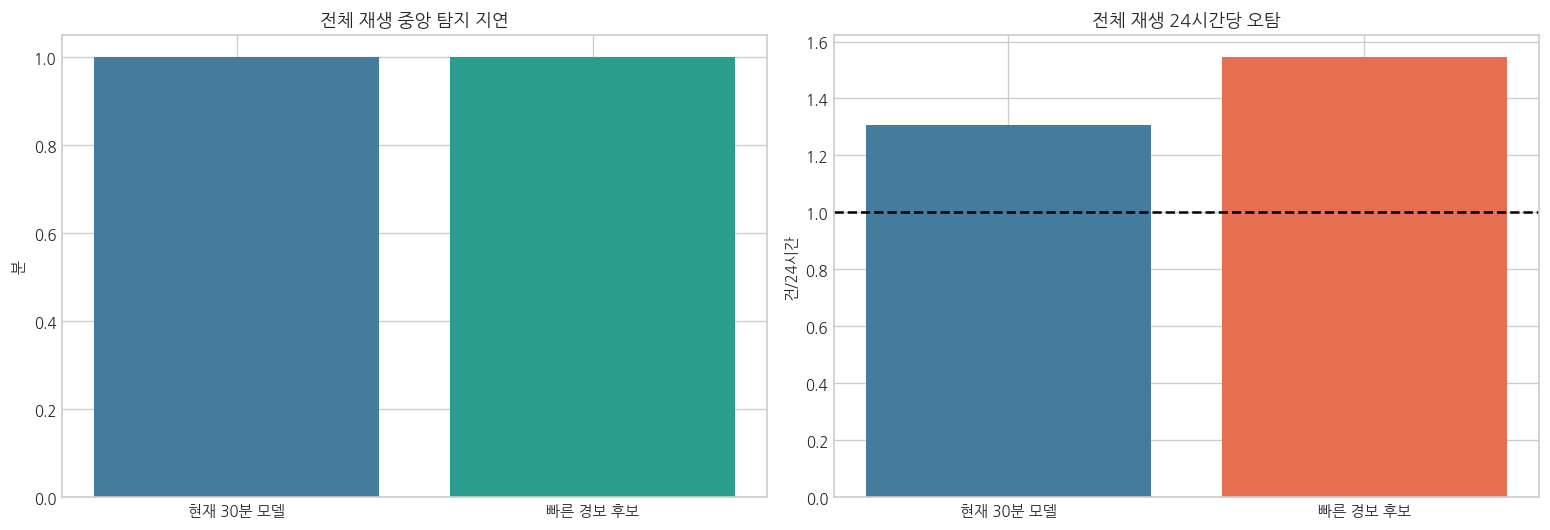

In [4]:
def continuous_metrics(data,prob_col,threshold,persistence):
    false_alerts=0;normal_minutes=0;event_rows=[]
    for reactor_id,g in data.groupby('reactor_id'):
        g=g.sort_values('timestamp').reset_index(drop=True);normal=g.fault_type.eq(0);boundary=normal.ne(normal.shift(fill_value=normal.iloc[0]));segment=boundary.cumsum()
        for _,s in g[normal].groupby(segment[normal]):normal_minutes+=len(s);false_alerts+=len(alert_indices(s[prob_col],threshold,persistence))
        change=g.fault_type.ne(g.fault_type.shift(fill_value=g.fault_type.iloc[0]));fault_segment=change.cumsum()
        for _,s in g[g.fault_type.ne(0)].groupby(fault_segment[g.fault_type.ne(0)]):
            idx=alert_indices(s[prob_col],threshold,persistence);event_rows.append({'reactor_id':reactor_id,'start':s.timestamp.iloc[0],'fault_type':int(s.fault_type.iloc[0]),'detected':len(idx)>0,'delay_min':float(idx[0]) if len(idx) else np.nan})
    events=pd.DataFrame(event_rows);return {'events':len(events),'detected':int(events.detected.sum()),'detection_rate':events.detected.mean(),'median_delay_min':events.delay_min.median(),'false_alerts':false_alerts,'false_alerts_per_24h':false_alerts/(normal_minutes/1440)},events

current_metrics,current_events=continuous_metrics(predictions,'current_probability',float(current_config['probability_threshold']),int(current_config['persistence_minutes']))
fast_metrics,fast_events=continuous_metrics(predictions,'fast_probability',float(selected_fast.threshold),int(selected_fast.persistence))
comparison=pd.DataFrame([{'model':'현재 30분 모델',**current_metrics},{'model':'빠른 경보 후보',**fast_metrics}]);print(comparison.to_string(index=False))
print('\n빠른 후보 유형별');print(fast_events.groupby('fault_type').agg(events=('detected','count'),detected=('detected','sum'),median_delay=('delay_min','median'),max_delay=('delay_min','max')).to_string())

fig,axes=plt.subplots(1,2,figsize=(13,4.5));axes[0].bar(comparison.model,comparison.median_delay_min,color=['#457b9d','#2a9d8f']);axes[0].set_title('전체 재생 중앙 탐지 지연');axes[0].set_ylabel('분');axes[1].bar(comparison.model,comparison.false_alerts_per_24h,color=['#457b9d','#e76f51']);axes[1].axhline(1,color='black',linestyle='--');axes[1].set_title('전체 재생 24시간당 오탐');axes[1].set_ylabel('건/24시간');plt.tight_layout();plt.show()


## 4. 결과 저장과 채택 판단

전체 재생 결과가 24시간당 오탐 1건 이하를 만족할 때만 빠른 후보를 채택합니다. 그렇지 않으면 현재 모델을 유지하고 추가 데이터에서 임계값을 다시 조정합니다.


In [5]:
current_meets_target=bool(current_metrics['detection_rate']==1 and current_metrics['false_alerts_per_24h']<=1)
adopt_fast=bool(fast_metrics['detection_rate']==1 and fast_metrics['false_alerts_per_24h']<=1 and fast_metrics['median_delay_min']<current_metrics['median_delay_min'])
MODEL_DIR=Path('models');RESULT_DIR=Path('data/modeling');MODEL_DIR.mkdir(exist_ok=True);RESULT_DIR.mkdir(parents=True,exist_ok=True)
decision='Adopt fast candidate' if adopt_fast else ('Keep current optimized model' if current_meets_target else 'No candidate is deployment-ready; keep the current model only as a development baseline')
result={'engineering_replay_not_independent':True,'current_model':current_metrics,'fast_candidate':fast_metrics,'fast_rule':{'threshold':float(selected_fast.threshold),'persistence':int(selected_fast.persistence)},'current_model_meets_full_replay_target':current_meets_target,'adopt_fast_candidate':adopt_fast,'decision':decision}
Path('models/continuous_replay_audit.json').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8');predictions.to_csv(RESULT_DIR/'continuous_replay_predictions.csv.gz',index=False,compression='gzip')
if adopt_fast:
    joblib.dump(fast_model,MODEL_DIR/'binary_fault_detector_fast_warning_hgb.joblib');config={'feature_columns':fast_features,'threshold':float(selected_fast.threshold),'persistence':int(selected_fast.persistence),'full_replay_metrics':fast_metrics,'warning':'Full replay is an engineering test, not an independent performance estimate.'};Path('models/binary_fault_detector_fast_warning_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(result,ensure_ascii=False,indent=2))


{
  "engineering_replay_not_independent": true,
  "current_model": {
    "events": 35,
    "detected": 35,
    "detection_rate": 1.0,
    "median_delay_min": 1.0,
    "false_alerts": 681,
    "false_alerts_per_24h": 1.3080449620447672
  },
  "fast_candidate": {
    "events": 35,
    "detected": 35,
    "detection_rate": 1.0,
    "median_delay_min": 1.0,
    "false_alerts": 804,
    "false_alerts_per_24h": 1.5442997789779631
  },
  "fast_rule": {
    "threshold": 0.275,
    "persistence": 2
  },
  "current_model_meets_full_replay_target": false,
  "adopt_fast_candidate": false,
  "decision": "No candidate is deployment-ready; keep the current model only as a development baseline"
}


## 5. 해석

전체 재생은 이벤트 주변 표본보다 훨씬 많은 정상 운전 시간을 포함하므로 실제 운영 경보량을 더 잘 보여줍니다. 빠른 후보가 이벤트 표본에서는 좋아도 전체 재생에서 오탐 목표를 넘으면 채택하지 않습니다.

이번 결과에서는 현재 모델과 빠른 후보 모두 전체 재생의 24시간당 오탐 1건 목표를 넘었습니다. 따라서 빠른 후보는 채택하지 않으며 현재 모델도 배포 준비가 끝난 모델로 보지 않습니다. 현재 모델은 다음 데이터 분할과 외부 검증을 위한 개발 기준선으로만 유지합니다.

전체 35개 이벤트의 중앙 지연이 매우 짧게 나타나는 이유는 train과 validation 이벤트가 재생 데이터에 포함됐기 때문입니다. 이 값은 탐지 성능으로 보고하지 않습니다. 독립 Test 8개에서 확인된 현재 모델의 중앙 지연 30분이 현재 사용 가능한 성능 추정치입니다.

이번 재생은 동일 데이터 안에서의 엔지니어링 검증입니다. 최종 성능 검증에는 새로운 기간 또는 새로운 반응기의 완전히 독립된 데이터가 필요합니다. 다음 단계에서는 채택된 이진 경보 시점에 맞춰 결함 유형 분류기를 다시 학습하고, 즉시·15분·30분 유형 예측을 단계적으로 비교해야 합니다.
